# Hemispheres Album: How Storms Move in the North and the South

Issue #26. Follows [notebook-guide.md](../docs/notebook-guide.md) and [data-guide.md](../docs/data-guide.md).

**What the album wants the listener to hear:** tropical cyclones in both hemispheres are born near the equator, drift west, head for the pole, and turn east. The two hemispheres do this as mirror images: northern storms go up and turn **right** (clockwise), southern storms go down and turn **left** (counterclockwise).

**What this notebook checks, in the source data (1981–2025, every storm that reached tropical storm strength):**

1. **Poleward**: storms in both hemispheres end up closer to their pole than where they started.
2. **West, then east**: storms move west in the tropics and east farther from the equator. Southern storms turn east sooner, at a lower latitude.
3. **The turn**: a storm that turns from west to east turns right in the north and left in the south, almost without exception.
4. **The spin** (not in the track data): northern storms spin counterclockwise, southern storms clockwise.
5. **One pair**: one northern and one southern storm, the series a track would play.

> The hemisphere comparison is **ours**. The EIC page below shows Atlantic storms only and says nothing about the Southern Hemisphere. The EIC source for this album is still open (see section 2).

Run with `npm run notebook`. The first run downloads IBTrACS (about 320 MB) into `data/hemispheres/raw/`.

In [1]:
import html
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import Markdown, display

pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 72, "axes.spines.top": False, "axes.spines.right": False})

RAW = Path("../data/hemispheres/raw")
(RAW / "api").mkdir(parents=True, exist_ok=True)

FIRST, LAST = 1981, 2025          # satellite era, whole seasons
TS_KT = 34                        # tropical storm strength
HEMI = {"N": "Northern Hemisphere", "S": "Southern Hemisphere"}
COLOR = {"N": "tab:red", "S": "tab:blue"}
CREDIT = "Source: IBTrACS v04r01 (NOAA/NCEI), USA agency (NHC/JTWC) best tracks, " + f"{FIRST}–{LAST}"


def download(name, url):
    path = RAW / name
    if not path.exists():
        with requests.get(url, stream=True, timeout=120) as r:
            r.raise_for_status()
            with open(path, "wb") as f:
                for chunk in r.iter_content(1 << 20):
                    f.write(chunk)
    return path


def svs_page(page_id):
    path = RAW / "api" / f"{page_id}.json"
    if not path.exists():
        path.write_text(requests.get(f"https://svs.gsfc.nasa.gov/api/{page_id}", timeout=60).text)
    return json.loads(path.read_text())


def plain(text):
    return re.sub(r"\s+", " ", html.unescape(re.sub(r"<[^>]+>", " ", text or ""))).strip()


def source_note(ax, text=CREDIT):
    ax.annotate(text, (0, 0), (0, -38), xycoords="axes fraction", textcoords="offset points", fontsize=8, color="gray")

## 1. Links

### 1.1 EIC page and what it cites

Built from the SVS API.

In [2]:
PAGES = [5072]


def cited(page_id):
    out = []
    for d in svs_page(page_id).get("datasets", []):
        name = d["name"] + (f" ({d['sensor'] or d['platform']})" if d.get("sensor") or d.get("platform") else "")
        out.append(f"[{name}]({d['url'].replace('http://', 'https://')})" if d.get("url") else f"{name}, no link")
    return "<br>".join(out) or "none"


rows = ["| SVS page | SVS API | Cited source |", "| --- | --- | --- |"]
for i in PAGES:
    rows.append(f"| [{i} {svs_page(i)['title']}](https://svs.gsfc.nasa.gov/{i}/) | "
                f"[api/{i}](https://svs.gsfc.nasa.gov/api/{i}) | {cited(i)} |")
display(Markdown("\n".join(rows)))

| SVS page | SVS API | Cited source |
| --- | --- | --- |
| [5072 Atlantic Hurricane Wind Speed Plots](https://svs.gsfc.nasa.gov/5072/) | [api/5072](https://svs.gsfc.nasa.gov/api/5072) | HURDAT2, no link<br>[Automated Tropical Cyclone Forecast (ATCF) - Best Track](https://ftp.nhc.noaa.gov/atcf/) |

### 1.2 What this notebook downloads

| Downloaded file | Dataset page | Note |
| --- | --- | --- |
| [ibtracs.ALL.list.v04r01.csv](https://www.ncei.noaa.gov/data/international-best-track-archive-for-climate-stewardship-ibtracs/v04r01/access/csv/ibtracs.ALL.list.v04r01.csv) | [IBTrACS (NOAA/NCEI)](https://www.ncei.noaa.gov/products/international-best-track-archive) | Substitute, public. 5072 cites HURDAT2 and the ATCF best track, which cover only the basins the US agencies watch, one file per basin. IBTrACS carries the same US best tracks (`USA_*` columns: NHC for the Atlantic and eastern Pacific, JTWC elsewhere) for every basin in one file. We read only those columns. |

## 2. What EIC says

5072 is the closest EIC page found so far: it cites the best-track data this notebook uses, but shows Atlantic storms only. **Picking the EIC page(s) for the album is still open (issue #26).**

In [3]:
for i in PAGES:
    display(Markdown(f"**[{i}](https://svs.gsfc.nasa.gov/{i}/) {svs_page(i)['title']}**\n\n> {plain(svs_page(i)['description'].split(' || ')[0])}"))

**[5072](https://svs.gsfc.nasa.gov/5072/) Atlantic Hurricane Wind Speed Plots**

> Atlantic Hurricane season plot of time vs. wind speed. This version shows:May through Decembereach year separately

## 3. Source data: storm tracks

[IBTrACS v04r01](https://www.ncei.noaa.gov/products/international-best-track-archive), US agency columns.

- one row per storm per time, every 6 hours at 00, 06, 12, 18 UTC (other rows dropped)
- `USA_LAT`, `USA_LON` in degrees, `USA_WIND` in knots (1-minute sustained)
- kept: main tracks, tropical stage (`NATURE == "TS"`), seasons 1981–2025, storms that reached 34 kt
- motion: from each 6-hour step, the eastward speed `u` and the poleward speed `vp` in km/h, and the heading (0° = east, 90° = north)

Credit: Knapp, K. R., et al. (2010). The International Best Track Archive for Climate Stewardship (IBTrACS). BAMS 91, 363–376. [doi:10.1175/2009BAMS2755.1](https://doi.org/10.1175/2009BAMS2755.1); Gahtan, J., et al. (2024). IBTrACS Project, Version 4r01. NOAA NCEI. [doi:10.25921/82ty-9e16](https://doi.org/10.25921/82ty-9e16)

In [4]:
IBTRACS = ("https://www.ncei.noaa.gov/data/international-best-track-archive-for-climate-stewardship-ibtracs"
           "/v04r01/access/csv/ibtracs.ALL.list.v04r01.csv")
path = download("ibtracs.ALL.list.v04r01.csv", IBTRACS)

cols = ["SID", "SEASON", "BASIN", "NAME", "ISO_TIME", "NATURE", "TRACK_TYPE", "USA_LAT", "USA_LON", "USA_WIND"]
# keep_default_na=False: the North Atlantic basin code is "NA".
raw = pd.read_csv(path, usecols=cols, skiprows=[1], keep_default_na=False, na_values=[" ", ""], low_memory=False)
raw["time"] = pd.to_datetime(raw["ISO_TIME"])
for c in ["USA_LAT", "USA_LON", "USA_WIND"]:
    raw[c] = pd.to_numeric(raw[c], errors="coerce")

d = raw[(raw.TRACK_TYPE == "main") & raw.SEASON.between(FIRST, LAST) & (raw.NATURE == "TS")
        & (raw.time.dt.hour % 6 == 0) & (raw.time.dt.minute == 0)].dropna(subset=["USA_LAT", "USA_LON"])
d = d.rename(columns={"USA_LAT": "lat", "USA_LON": "lon", "USA_WIND": "wind"})
d = d[d.SID.isin(d.groupby("SID").wind.max().loc[lambda s: s >= TS_KT].index)].sort_values(["SID", "time"]).copy()
d["hemi"] = np.where(d.groupby("SID").lat.transform("first") >= 0, "N", "S")

R = 6371.0
g = d.groupby("SID")
dlon = (d.lon - g.lon.shift() + 180) % 360 - 180
hours = (d.time - g.time.shift()).dt.total_seconds() / 3600
d["u"] = np.radians(dlon) * R * np.cos(np.radians((d.lat + g.lat.shift()) / 2)) / hours
d["v"] = np.radians(d.lat - g.lat.shift()) * R / hours
d["vp"] = d.v * np.where(d.hemi == "N", 1, -1)          # poleward
d["heading"] = np.degrees(np.arctan2(d.v, d.u))          # 0 = east, 90 = north
d["east"] = (d.lon - g.lon.transform("first") + 180) % 360 - 180   # degrees east of genesis
d["pole"] = (d.lat - g.lat.transform("first")) * np.where(d.hemi == "N", 1, -1)  # degrees poleward of genesis

print(f"{d.SID.nunique()} storms, {len(d)} six-hour records")
d.groupby(["hemi", "BASIN"]).SID.nunique().unstack(0).fillna(0).astype(int)

3781 storms, 97287 six-hour records


hemi,N,S
BASIN,,
EP,797,0
NA,598,0
NI,204,0
SA,0,1
SI,0,720
SP,0,428
WP,1134,0


In [5]:
def storm_summary(s):
    m = s.dropna(subset=["u"])
    n = len(m) // 3
    first, last = m.iloc[:n], m.iloc[-n:]
    h1 = np.degrees(np.arctan2(first.v.sum(), first.u.sum()))
    h2 = np.degrees(np.arctan2(last.v.sum(), last.u.sum()))
    step = (np.diff(m.heading) + 180) % 360 - 180
    return pd.Series({
        "name": s.NAME.iloc[0], "season": s.SEASON.iloc[0], "basin": s.BASIN.iloc[0], "hemi": s.hemi.iloc[0],
        "lat0": s.lat.iloc[0], "pole": s.pole.iloc[-1], "east": s.east.iloc[-1], "vmax": s.wind.max(),
        "days": (s.time.iloc[-1] - s.time.iloc[0]).total_seconds() / 86400,
        "turn": (h2 - h1 + 180) % 360 - 180,             # + left (CCW), - right (CW)
        "recurve": first.u.sum() < 0 < last.u.sum(),      # west first, east at the end
        "wiggle": np.abs(step).sum() / max(abs(step.sum()), 1),
    })


st = d[d.groupby("SID").SID.transform("size") >= 6].groupby("SID").apply(storm_summary, include_groups=False)
st["side"] = np.select([st.turn > 20, st.turn < -20], ["left", "right"], "straight")
print(f"{len(st)} storms with at least 6 records (36 hours)")

3720 storms with at least 6 records (36 hours)


## 4. Information 1, poleward: both hemispheres head for their pole

Every track drawn from the point where it became a storm. Northern storms fan out upward, southern storms downward.

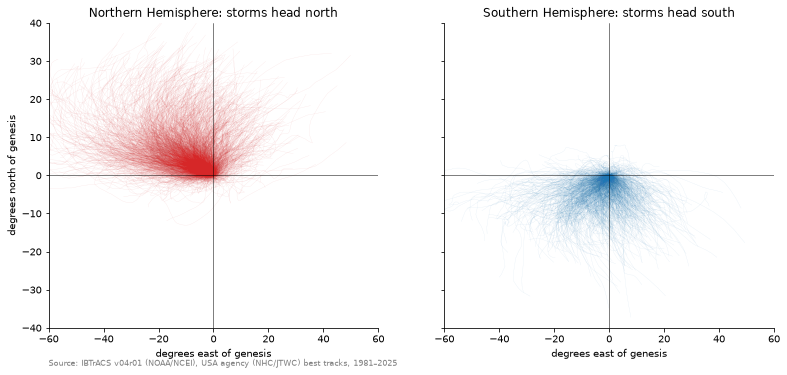

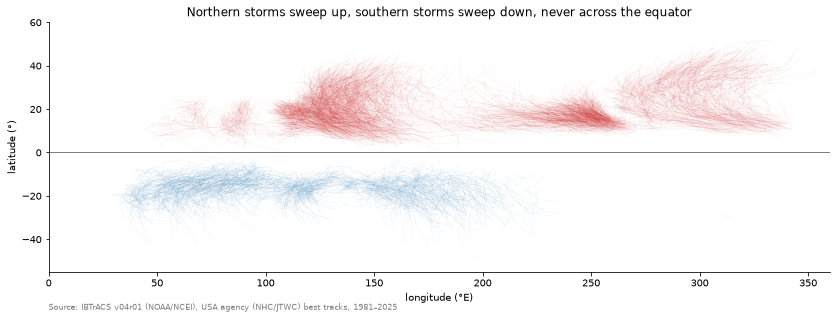

,storms,ended_poleward,median_genesis_lat,median_poleward_deg
hemi,,,,
N,2620,0.95,13.9,8.9
S,1100,0.96,12.2,9.2


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, sharey=True)
for ax, h in zip(axes, "NS"):
    for _, s in d[(d.hemi == h) & d.SID.isin(st.index)].groupby("SID"):
        ax.plot(s.east, s.lat - s.lat.iloc[0], color=COLOR[h], lw=0.3, alpha=0.12)
    ax.axhline(0, color="k", lw=0.5); ax.axvline(0, color="k", lw=0.5)
    ax.set_xlim(-60, 60); ax.set_ylim(-40, 40)
    ax.set_title(f"{HEMI[h]}: storms head {'north' if h == 'N' else 'south'}")
    ax.set_xlabel("degrees east of genesis")
axes[0].set_ylabel("degrees north of genesis")
source_note(axes[0])
plt.show()

fig, ax = plt.subplots(figsize=(14, 4.5))
for _, s in d[d.SID.isin(st.index)].groupby("SID"):
    lon = s.lon % 360
    lon = lon.mask(np.abs(lon.diff()) > 180)
    ax.plot(lon, s.lat, color=COLOR[s.hemi.iloc[0]], lw=0.25, alpha=0.15)
ax.axhline(0, color="k", lw=0.5)
ax.set_xlim(0, 360); ax.set_ylim(-55, 60)
ax.set_xlabel("longitude (°E)"); ax.set_ylabel("latitude (°)")
ax.set_title("Northern storms sweep up, southern storms sweep down, never across the equator")
source_note(ax)
plt.show()

poleward = st.assign(ended_poleward=st.pole > 0).groupby("hemi").agg(
    storms=("name", "size"), ended_poleward=("ended_poleward", "mean"),
    median_genesis_lat=("lat0", lambda x: x.abs().median()), median_poleward_deg=("pole", "median"))
poleward.round(2)

## 5. Information 2, west then east: southern storms turn east sooner

Mean motion of every 6-hour step, by distance from the equator. Westward below the line, eastward above it.

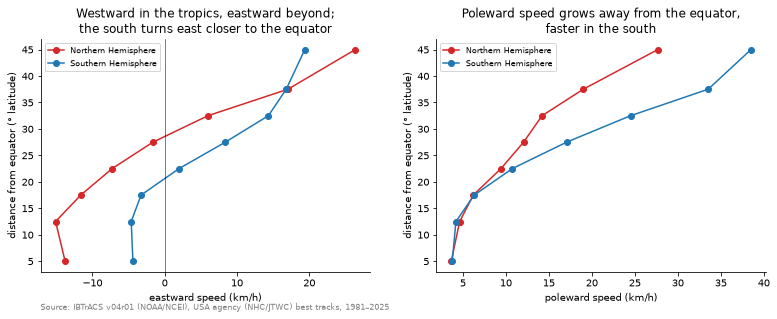

u          vp      
hemi         N     S     N     S
band                            
(0, 10]  -13.8  -4.4   3.6   3.8
(10, 15] -15.1  -4.6   4.6   4.2
(15, 20] -11.6  -3.3   6.2   6.3
(20, 25]  -7.3   2.0   9.4  10.7
(25, 30]  -1.6   8.4  12.1  17.1
(30, 35]   6.0  14.3  14.2  24.5
(35, 40]  17.0  16.8  19.0  33.5
(40, 50]  26.4  19.4  27.7  38.5

In [7]:
BANDS = [0, 10, 15, 20, 25, 30, 35, 40, 50]
m = d[d.SID.isin(st.index)].dropna(subset=["u"]).copy()
m["band"] = pd.cut(m.lat.abs(), BANDS)
by_band = m.groupby(["hemi", "band"], observed=True)[["u", "vp"]].mean().unstack(0)
mid = [b.mid for b in by_band.index]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for h in "NS":
    axes[0].plot(by_band["u"][h], mid, "o-", color=COLOR[h], label=HEMI[h])
    axes[1].plot(by_band["vp"][h], mid, "o-", color=COLOR[h], label=HEMI[h])
axes[0].axvline(0, color="k", lw=0.5)
axes[0].set_title("Westward in the tropics, eastward beyond;\nthe south turns east closer to the equator")
axes[0].set_xlabel("eastward speed (km/h)")
axes[1].set_title("Poleward speed grows away from the equator,\nfaster in the south")
axes[1].set_xlabel("poleward speed (km/h)")
for ax in axes:
    ax.set_ylabel("distance from equator (° latitude)"); ax.legend(fontsize=8)
source_note(axes[0])
plt.show()
by_band.round(1)

In [8]:
def turning_latitude(s):
    # Latitude of the first step after which the storm keeps moving east (5-step running mean of u).
    u = s.u.rolling(5, center=True, min_periods=3).mean()
    east = (u > 0).to_numpy()
    for i in range(len(east)):
        if east[i:].all():
            return abs(s.lat.iloc[i])
    return np.nan


rec = st[st.recurve]
turn_lat = d[d.SID.isin(rec.index)].dropna(subset=["u"]).groupby("SID").apply(turning_latitude, include_groups=False)
rec = rec.assign(turn_lat=turn_lat)
rec.groupby("hemi").turn_lat.describe()[["count", "25%", "50%", "75%"]].round(1)

,count,25%,50%,75%
hemi,,,,
N,736.0,19.5,24.9,30.1
S,284.0,15.1,18.4,21.4


## 6. Information 3, the turn: right in the north, left in the south

For each storm, the heading of its first third against the heading of its last third. A change of more than 20° counts as a turn.

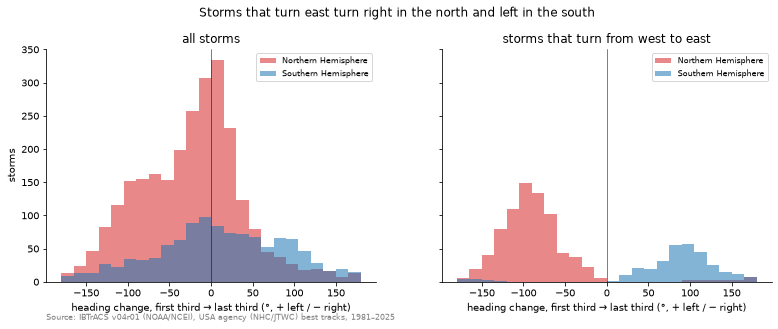

all storms                turn west → east               
side       left right straight             left right straight
hemi                                                          
N           528  1260      832               19   735       13
S           502   358      240              298    11        2

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
bins = np.arange(-180, 181, 15)
for ax, (label, sel) in zip(axes, [("all storms", st), ("storms that turn from west to east", rec)]):
    for h in "NS":
        ax.hist(sel[sel.hemi == h].turn, bins=bins, color=COLOR[h], alpha=0.55, label=HEMI[h])
    ax.axvline(0, color="k", lw=0.5)
    ax.set_xlabel("heading change, first third → last third (°, + left / − right)")
    ax.set_title(label)
    ax.legend(fontsize=8)
axes[0].set_ylabel("storms")
fig.suptitle("Storms that turn east turn right in the north and left in the south", y=1.02)
source_note(axes[0])
plt.show()

table = pd.concat({"all storms": pd.crosstab(st.hemi, st.side), "turn west → east": pd.crosstab(rec.hemi, rec.side)}, axis=1)
table

In [10]:
pd.crosstab([st.hemi, st.basin], st.side).assign(
    share_turning_east=st.groupby(["hemi", "basin"]).recurve.mean().round(2))

side        left  right  straight  share_turning_east
hemi basin                                           
N    EP      157    267       349                0.14
     NA       90    332       148                0.39
     NI       63     70        52                0.23
     WP      218    591       283                0.36
S    SA        0      1         0                0.00
     SI      317    216       152                0.29
     SP      185    141        88                0.28

- Over **all** storms the difference is clear in the north (right far more than left) but weak in the south: many southern storms wobble, stall or drift without a clean turn.
- Among storms that **turn from west to east** (about 3 in 10 in both hemispheres), the rule is almost absolute: right in the north, left in the south. This is the contrast the album can play without hedging.
- So the tracks should be storms that do turn east, not storms picked at random.

## 7. Information 4, the spin: not in the track data

Best-track data records where a storm is, not how its winds rotate. The spin direction is fixed by the hemisphere: counterclockwise in the north, clockwise in the south (the Coriolis effect). The album can show it as a given (a symbol that spins one way or the other), not as a series from this dataset. Whether an EIC page states it is to be checked when the EIC page is chosen.

## 8. One pair: the series a track would play

Candidates: strong (≥ 100 kt), recent (2010 on), turned from west to east in their hemisphere's direction, with a clean turn (`wiggle` near 1 means the heading turns one way without looping back).

In [11]:
cand = rec[(rec.season >= 2010) & (rec.vmax >= 100) & (rec.days.between(5, 14))
           & (rec.side == np.where(rec.hemi == "N", "right", "left"))]
cand = cand.assign(abs_turn=cand.turn.abs()).sort_values("wiggle")
show = ["name", "season", "basin", "vmax", "days", "turn", "turn_lat", "pole", "east", "wiggle"]
display(cand[cand.hemi == "N"].head(8)[show].round(1))
display(cand[cand.hemi == "S"].head(8)[show].round(1))

,name,season,basin,vmax,days,turn,turn_lat,pole,east,wiggle
SID,,,,,,,,,,
2020279N16284,DELTA,2020,NA,120.0,5.8,-86.0,27.5,16.1,-15.2,1.2
2014285N16305,GONZALO,2014,NA,125.0,7.5,-101.3,25.6,31.4,5.8,1.2
2010236N12341,EARL,2010,NA,125.0,10.5,-97.7,33.0,31.4,-35.4,1.3
2019314N12172,FENGSHEN,2019,WP,115.0,6.0,-135.5,22.4,12.7,-11.3,1.4
2016278N16181,SONGDA,2016,WP,130.0,5.8,-132.3,27.2,18.0,-2.0,1.4
2014254N14327,EDOUARD,2014,NA,105.0,8.0,-122.3,31.7,23.7,-1.6,1.5
2017333N06082,OCKHI,2017,NI,100.0,6.5,-92.8,14.1,12.3,-10.7,1.5
2025261N19312,GABRIELLE,2025,NA,120.0,7.8,-140.3,30.4,17.4,11.0,1.6


,name,season,basin,vmax,days,turn,turn_lat,pole,east,wiggle
SID,,,,,,,,,,
2023055S14184,JUDY,2023,SP,110.0,6.2,149.4,17.0,13.9,3.0,1.5
2020072S14054,HEROLD,2020,SI,100.0,6.2,124.3,15.0,10.7,16.5,2.0
2010069S12188,TOMAS,2010,SP,115.0,6.2,101.9,16.2,18.5,2.7,2.1
2012018S16041,FUNSO,2012,SI,115.0,9.8,97.1,22.9,11.0,-0.1,2.1
2014004S17183,IAN,2014,SP,130.0,8.8,176.3,16.7,12.9,7.9,2.2
2019035S13070,FUNANI,2019,SI,120.0,5.0,94.7,16.9,15.7,7.5,2.3
2018064S16172,HOLA,2018,SP,105.0,5.5,129.9,17.8,11.3,1.1,2.5
2012039S14075,GIOVANNA,2012,SI,120.0,11.8,161.9,24.6,11.4,-15.4,2.6


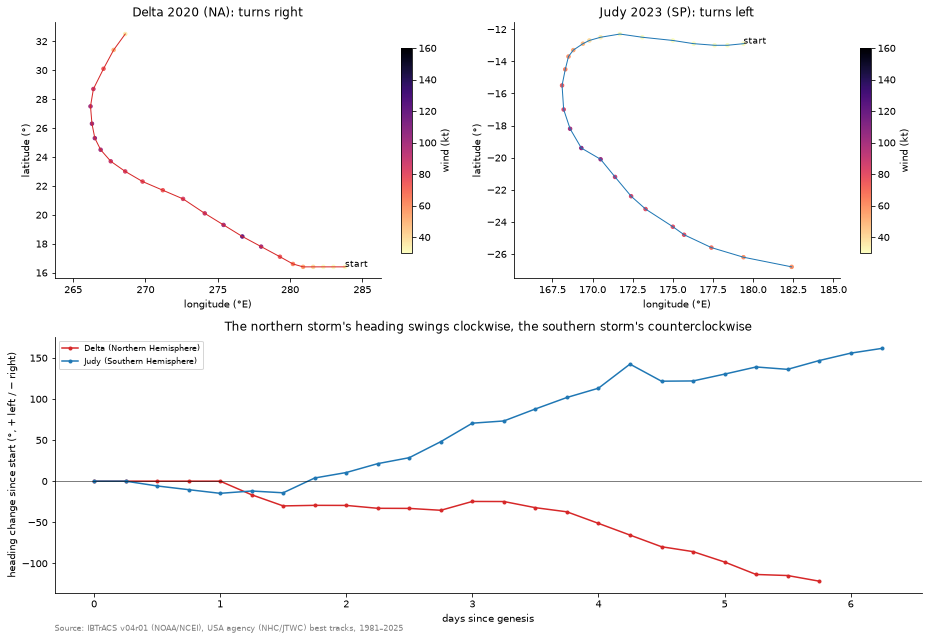

In [12]:
pair = {h: cand[cand.hemi == h].index[0] for h in "NS"}
fig = plt.figure(figsize=(13, 9))
for k, h in enumerate("NS"):
    s = d[d.SID == pair[h]]
    info = st.loc[pair[h]]
    ax = fig.add_subplot(2, 2, k + 1)
    sc = ax.scatter(s.lon % 360, s.lat, c=s.wind, cmap="magma_r", s=12, vmin=30, vmax=160)
    ax.plot(s.lon % 360, s.lat, color=COLOR[h], lw=1)
    ax.annotate("start", (s.lon.iloc[0] % 360, s.lat.iloc[0]), fontsize=9)
    ax.set_aspect("equal", adjustable="datalim")
    ax.set_title(f"{info['name'].title()} {info.season} ({info.basin}): turns {info.side}")
    ax.set_xlabel("longitude (°E)"); ax.set_ylabel("latitude (°)")
    fig.colorbar(sc, ax=ax, label="wind (kt)", shrink=0.8)

    ax = fig.add_subplot(2, 1, 2) if k == 0 else ax2
    ax2 = ax
    t = (s.time - s.time.iloc[0]).dt.total_seconds() / 86400
    heading = np.degrees(np.unwrap(np.radians(s.heading.bfill())))
    ax.plot(t, heading - heading[0], "o-", ms=3, color=COLOR[h], label=f"{info['name'].title()} ({HEMI[h]})")
ax2.axhline(0, color="k", lw=0.5)
ax2.set_xlabel("days since genesis"); ax2.set_ylabel("heading change since start (°, + left / − right)")
ax2.set_title("The northern storm's heading swings clockwise, the southern storm's counterclockwise")
ax2.legend(fontsize=8)
source_note(ax2)
fig.tight_layout()
plt.show()

In [13]:
def track_series(sid):
    s = d[d.SID == sid]
    return pd.DataFrame({
        "time": s.time, "lat": s.lat, "lon": s.lon, "wind_kt": s.wind,
        "east_of_genesis_deg": s.east.round(2), "poleward_of_genesis_deg": s.pole.round(2),
        "heading_deg": s.heading.round(1),
    }).reset_index(drop=True)


for h in "NS":
    s = track_series(pair[h])
    print(f"{st.loc[pair[h], 'name']} {st.loc[pair[h], 'season']}: {len(s)} records, "
          f"{s.time.iloc[0]:%Y-%m-%d %H} to {s.time.iloc[-1]:%Y-%m-%d %H} UTC")
    display(s.iloc[::4])

DELTA 2020: 24 records, 2020-10-04 18 to 2020-10-10 12 UTC


,time,lat,lon,wind_kt,east_of_genesis_deg,poleward_of_genesis_deg,heading_deg
0,2020-10-04 18:00:00,16.4,-76.2,30.0,0.0,0.0,NaN
4,2020-10-05 18:00:00,16.4,-79.1,55.0,-2.9,0.0,180.0
8,2020-10-06 18:00:00,18.5,-83.3,120.0,-7.1,2.1,150.5
12,2020-10-07 18:00:00,21.7,-88.8,75.0,-12.6,5.3,155.3
16,2020-10-08 18:00:00,24.5,-93.1,100.0,-16.9,8.1,128.6
20,2020-10-09 18:00:00,28.7,-93.6,90.0,-17.4,12.3,81.6


JUDY 2023: 26 records, 2023-02-25 06 to 2023-03-03 12 UTC


,time,lat,lon,wind_kt,east_of_genesis_deg,poleward_of_genesis_deg,heading_deg
0,2023-02-25 06:00:00,-12.9,179.4,25.0,0.0,-0.0,NaN
4,2023-02-26 06:00:00,-12.7,175.0,25.0,-4.4,-0.2,171.0
8,2023-02-27 06:00:00,-12.7,169.8,40.0,-9.6,-0.2,-163.7
12,2023-02-28 06:00:00,-14.5,168.3,65.0,-11.1,1.6,-103.6
16,2023-03-01 06:00:00,-19.4,169.3,110.0,-10.1,6.5,-61.1
20,2023-03-02 06:00:00,-23.2,173.3,80.0,-6.1,10.3,-44.0
24,2023-03-03 06:00:00,-26.2,179.4,60.0,0.0,13.3,-18.4


## 9. Information summary

What the music can carry, from the numbers above.

In [14]:
pct = lambda x: f"{x:.0%}"
right_n, left_s = pd.crosstab(rec.hemi, rec.side).loc["N", "right"], pd.crosstab(rec.hemi, rec.side).loc["S", "left"]
summary = pd.DataFrame([
    ["Poleward", "Both hemispheres head for their pole",
     f"ended poleward: N {pct(poleward.loc['N', 'ended_poleward'])}, S {pct(poleward.loc['S', 'ended_poleward'])}",
     "latitude over time"],
    ["West, then east", "Westward in the tropics, eastward beyond; the south turns sooner",
     f"median turning latitude: N {rec[rec.hemi == 'N'].turn_lat.median():.1f}°, S {rec[rec.hemi == 'S'].turn_lat.median():.1f}°",
     "degrees east of genesis over time"],
    ["The turn", "Storms that turn east turn right in the north, left in the south",
     f"N right {right_n} of {(rec.hemi == 'N').sum()}, S left {left_s} of {(rec.hemi == 'S').sum()}",
     "heading over time"],
    ["The spin", "Counterclockwise in the north, clockwise in the south", "not in the data (fixed by hemisphere)", "none"],
], columns=["information", "statement", "key number", "series"])
summary

,information,statement,key number,series
0,Poleward,Both hemispheres head for their pole,"ended poleward: N 95%, S 96%",latitude over time
1,"West, then east","Westward in the tropics, eastward beyond; the south turns sooner","median turning latitude: N 24.9°, S 18.4°",degrees east of genesis over time
2,The turn,"Storms that turn east turn right in the north, left in the south","N right 735 of 767, S left 298 of 311",heading over time
3,The spin,"Counterclockwise in the north, clockwise in the south",not in the data (fixed by hemisphere),none


## 10. Track candidates

Each candidate storm is one 6-hourly series (section 8): latitude, longitude, wind, degrees east and poleward of genesis, heading. The table below lists, per hemisphere and basin, the cleanest strong storm that turns its hemisphere's way.

In [15]:
best = cand.sort_values("wiggle").groupby("basin").head(1)
best.assign(records=lambda x: (x.days * 4 + 1).round().astype(int))[
    ["name", "season", "hemi", "basin", "vmax", "days", "records", "turn", "turn_lat", "wiggle"]].round(1)

,name,season,hemi,basin,vmax,days,records,turn,turn_lat,wiggle
SID,,,,,,,,,,
2020279N16284,DELTA,2020,N,NA,120.0,5.8,24,-86.0,27.5,1.2
2019314N12172,FENGSHEN,2019,N,WP,115.0,6.0,25,-135.5,22.4,1.4
2023055S14184,JUDY,2023,S,SP,110.0,6.2,26,149.4,17.0,1.5
2017333N06082,OCKHI,2017,N,NI,100.0,6.5,27,-92.8,14.1,1.5
2015288N10243,OLAF,2015,N,EP,130.0,12.2,50,-129.9,15.6,1.6
2020072S14054,HEROLD,2020,S,SI,100.0,6.2,26,124.3,15.0,2.0
